# Figure 4 — panels (muscle stem cells: young, aged, geriatric)
Draws every Figure 4 / Supplementary Figure 4Sa / 4Sb panel from the tables in `data/muscle/` (written by
`muscle_analysis.ipynb`) → `figures/<panel>.svg`, named by final panel letter. Figure 4 and 4Sa are assembled in
Illustrator (`../../illustrator-figures/Figure4.ai`, `Figure4Sa.ai`; panel 4a, the schematic, lives there); 4Sb is
assembled by `muscle_pages.ipynb`. Sections follow the analyses; each final panel has its own header. Panels
use matplotlib's default font, as published.

In [1]:
import sys

import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap, to_rgb
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

sys.path.insert(0, "..")                                # shared modules
import kcore                                            # chromosome strips + paper-wide chromosome palette

DATA = "data/muscle"
FIG = "figures"
SIG = 0.05

YOUNG = "#2c7fb8"                                      # young-specific
OLD = "#d7301f"                                        # old-specific (aged / geriatric)
GREY = "#BFBFBF"                                       # not significant
BOTH = "#7b3294"                                       # enriched in both states
AGED_C = "#fb9a99"                                     # aged-specific (aged vs geriatric)
GERI_C = "#e31a1c"                                     # geriatric-specific (aged vs geriatric)
PAIRS = [("young_vs_aged", "young", "aged"), ("young_vs_geriatric", "young", "geriatric")]
AG = "aged_vs_geriatric"


def label_of(name):
    """Pathway label: the full set id incl. its source tag, e.g. '(H)', '(KEGG)'."""
    return name


def light(c, f=0.55):
    """Opaque tint of a colour (mixed toward white), so Illustrator sees a flat fill."""
    return tuple(1 - f * (1 - x) for x in to_rgb(c))


folds = {p: pd.read_csv(f"{DATA}/fold_enrichment_{p}.csv", index_col=0) for p in [p for p, _, _ in PAIRS] + [AG]}
gsea = {p: pd.read_csv(f"{DATA}/gsea_{p}.csv").set_index("Term") for p in [p for p, _, _ in PAIRS] + [AG]}

## Pathway colocalization
Diverging fold enrichment of age-specific interchromosomal contacts: right = older-group-specific, left = younger;
coloured if FDR < 0.05 (else grey), `*` = FDR < 0.05, baseline at fold 1. The two young-vs-older panels share one
x-range.

In [2]:
# shared x-range of the two young-vs-older panels: pathways significant in either contrast
sig_paths = set()
for p, _, _ in PAIRS:
    f = folds[p]
    sig_paths |= set(f.index[f.sig_young | f.sig_old])
order = sorted(sig_paths, key=lambda s: np.mean([folds[p].loc[s, "signed_effect"] for p, _, _ in PAIRS]))
maxdev = max((folds[p].loc[order, ["fold_young", "fold_old"]].max().max() - 1) for p, _, _ in PAIRS)
half = np.ceil(maxdev * 4) / 4                          # round up to the nearest 0.25
xticks = np.arange(0, half + 1e-6, 0.5)
xtick_pos = np.concatenate([1 - xticks[::-1], 1 + xticks[1:]])
xtick_lab = [f"{1 + t:.2f}".rstrip("0").rstrip(".") for t in xticks[::-1]] + \
            [f"{1 + t:.2f}".rstrip("0").rstrip(".") for t in xticks[1:]]


def panel_A(ax, pair, title, order):
    """Diverging fold-enrichment bars for one young-vs-older contrast."""
    f = folds[pair]
    for i, s in enumerate(order):
        fo = f.loc[s, "fold_old"]
        fy = f.loc[s, "fold_young"]
        so = f.loc[s, "sig_old"]
        sy = f.loc[s, "sig_young"]
        ax.barh(i, max(0, fo - 1), left=1, height=0.72, color=OLD if so else GREY, zorder=3)
        ax.barh(i, -max(0, fy - 1), left=1, height=0.72, color=YOUNG if sy else GREY, zorder=3)
        if so and fo > 1:
            ax.text(fo + 0.02, i, "*", va="center", color=OLD, fontsize=14)
        if sy and fy > 1:
            ax.text((2 - fy) - 0.02, i, "*", va="center", ha="right", color=YOUNG, fontsize=14)
    ax.axvline(1, color="k", lw=0.8)
    ax.set_xlim(1 - half, 1 + half)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(xtick_lab, fontsize=12)
    ax.set_yticks(range(len(order)))
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Fold enrichment of age-specific contacts", fontsize=14)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)


legend = [plt.matplotlib.patches.Patch(color=YOUNG, label="Young-specific"),
          plt.matplotlib.patches.Patch(color=OLD, label="Old-specific"),
          mlines.Line2D([], [], marker="$*$", color="k", linestyle="none", markersize=9, label="FDR < 0.05")]


def colocalization_panel(pair, title, name):
    """One contrast's panel, showing only pathways significant in that contrast; saves figures/<name>."""
    f = folds[pair]
    order_p = sorted(f.index[f["sig_young"] | f["sig_old"]], key=lambda s: f.loc[s, "signed_effect"])
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(order_p) + 1))
    panel_A(ax, pair, title, order_p)
    ax.set_yticklabels([label_of(s) for s in order_p], fontsize=14)
    ax.legend(handles=legend, loc="lower right", frameon=True, edgecolor="black", fontsize=12)
    plt.tight_layout()
    plt.savefig(f"{FIG}/{name}.svg", bbox_inches="tight")
    plt.show()

### Figure 4b — Colocalized pathways, young (2 mo) vs geriatric (28–32 mo)

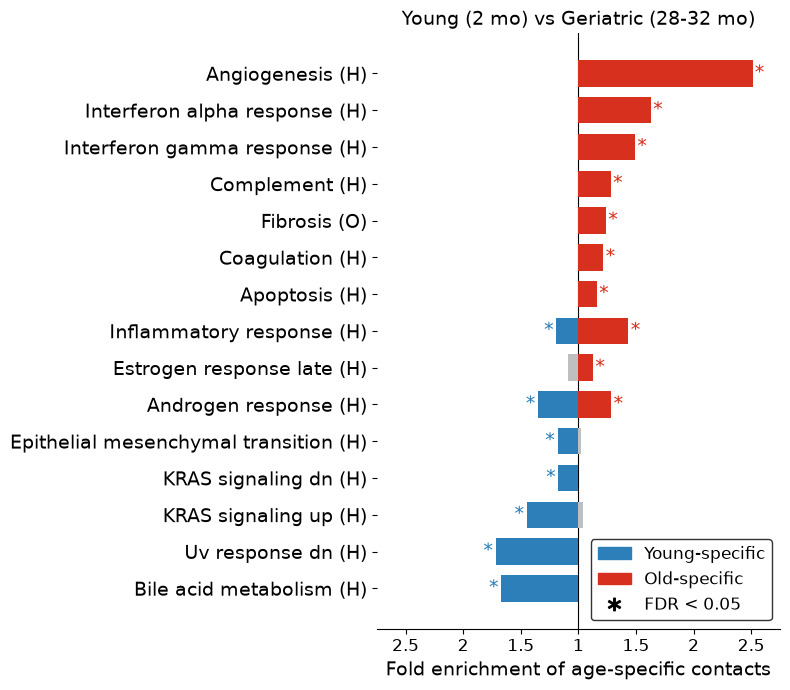

In [3]:
colocalization_panel("young_vs_geriatric", "Young (2 mo) vs Geriatric (28-32 mo)", "fig4b_colocalization_young_vs_geriatric")

### Supplementary Figure 4Sa, panel b — Colocalized pathways, young (2 mo) vs aged (23–24 mo)

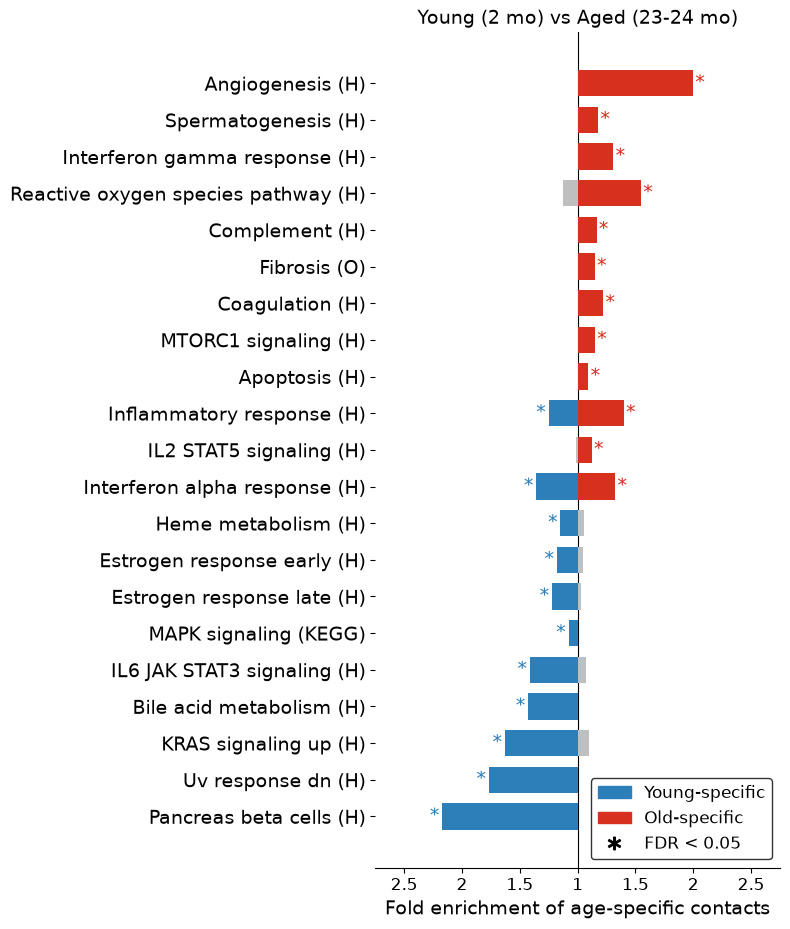

In [4]:
colocalization_panel("young_vs_aged", "Young (2 mo) vs Aged (23-24 mo)", "fig4Sa_b_colocalization_young_vs_aged")

### Figure 4e — Colocalized pathways, aged (23–24 mo) vs geriatric (28–32 mo)
Light red = aged-specific (left), dark red = geriatric-specific (right).

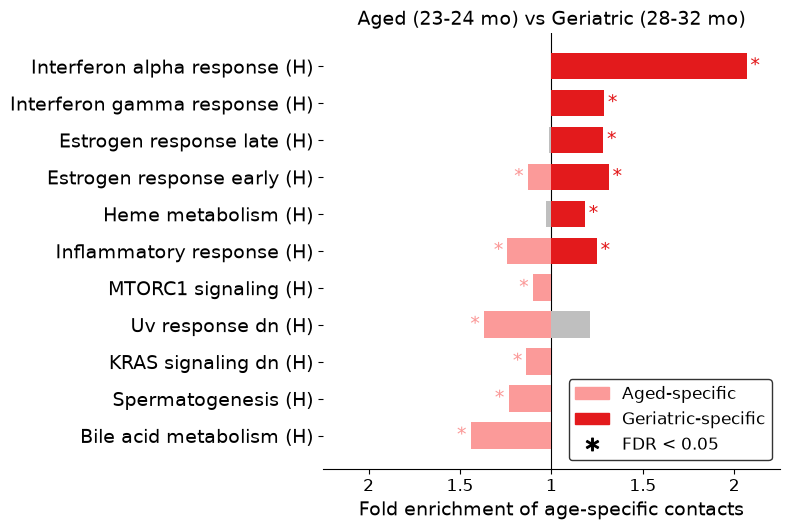

In [5]:
f_ag = folds[AG]
order_ag = sorted(f_ag.index[f_ag["sig_young"] | f_ag["sig_old"]], key=lambda s: f_ag.loc[s, "signed_effect"])
maxdev_ag = f_ag.loc[order_ag, ["fold_young", "fold_old"]].max().max() - 1
half_ag = np.ceil(maxdev_ag * 4) / 4
xticks_ag = np.arange(0, half_ag + 1e-6, 0.5)
xpos_ag = np.concatenate([1 - xticks_ag[::-1], 1 + xticks_ag[1:]])
xlab_ag = [f"{1 + t:.2f}".rstrip("0").rstrip(".") for t in xticks_ag[::-1]] + \
          [f"{1 + t:.2f}".rstrip("0").rstrip(".") for t in xticks_ag[1:]]

fig, ax = plt.subplots(figsize=(8, 0.4 * len(order_ag) + 1))
for i, s in enumerate(order_ag):
    fo = f_ag.loc[s, "fold_old"]                       # geriatric
    fy = f_ag.loc[s, "fold_young"]                     # aged
    so = f_ag.loc[s, "sig_old"]
    sy = f_ag.loc[s, "sig_young"]
    ax.barh(i, max(0, fo - 1), left=1, height=0.72, color=GERI_C if so else GREY, zorder=3)
    ax.barh(i, -max(0, fy - 1), left=1, height=0.72, color=AGED_C if sy else GREY, zorder=3)
    if so and fo > 1:
        ax.text(fo + 0.02, i, "*", va="center", color=GERI_C, fontsize=14)
    if sy and fy > 1:
        ax.text((2 - fy) - 0.02, i, "*", va="center", ha="right", color=AGED_C, fontsize=14)
ax.axvline(1, color="k", lw=0.8)
ax.set_xlim(1 - half_ag, 1 + half_ag)
ax.set_xticks(xpos_ag)
ax.set_xticklabels(xlab_ag, fontsize=12)
ax.set_yticks(range(len(order_ag)))
ax.set_title("Aged (23-24 mo) vs Geriatric (28-32 mo)", fontsize=14)
ax.set_xlabel("Fold enrichment of age-specific contacts", fontsize=14)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
legend_ag = [plt.matplotlib.patches.Patch(color=AGED_C, label="Aged-specific"),
             plt.matplotlib.patches.Patch(color=GERI_C, label="Geriatric-specific"),
             mlines.Line2D([], [], marker="$*$", color="k", linestyle="none", markersize=9, label="FDR < 0.05")]
ax.set_yticklabels([label_of(s) for s in order_ag], fontsize=14)
ax.legend(handles=legend_ag, loc="lower right", frameon=True, edgecolor="black", fontsize=12)
plt.tight_layout()
plt.savefig(f"{FIG}/fig4e_colocalization_aged_vs_geriatric.svg", bbox_inches="tight")
plt.show()

## Pathway expression (GSEA)
Pathways at GSEA FDR < 0.05 in each contrast, ordered by NES; stem 0 → NES, dot size = FDR; red = higher in the older
group, blue = higher in the younger (aged vs geriatric: dark red = geriatric, light red = aged).

In [6]:
def pval_to_size(p):
    """Dot size from GSEA FDR (CD8 convention: bigger dot = smaller q)."""
    return np.log(p + 0.005) * -3


def sig_terms(pair):
    """Gene sets at GSEA FDR < 0.05 in a contrast."""
    g = gsea[pair].copy()
    g["FDR q-val"] = pd.to_numeric(g["FDR q-val"], errors="coerce")
    return set(g.index[g["FDR q-val"] < SIG])


def lollipop(ax, pair, ordering, title, up_color, down_color):
    """GSEA lollipop; colour by direction where significant in this contrast, else grey."""
    g = gsea[pair]
    present = [s for s in ordering if s in g.index]
    y = np.arange(len(present))
    nes = pd.to_numeric(g.loc[present, "NES"], errors="coerce").values
    pv = pd.to_numeric(g.loc[present, "FDR q-val"], errors="coerce").fillna(1.0).clip(lower=0.001).values   # dot size
    fdr = pd.to_numeric(g.loc[present, "FDR q-val"], errors="coerce").fillna(1.0).values
    colors = [(up_color if n >= 0 else down_color) if f < SIG else GREY for n, f in zip(nes, fdr)]
    ax.hlines(y=y, xmin=0, xmax=nes, color="black", lw=0.8, zorder=1)
    for i in range(len(present)):
        ax.plot(nes[i], y[i], "o", color=colors[i], markersize=pval_to_size(pv[i]), zorder=3)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([label_of(s) for s in present], fontsize=14)
    ax.set_xlabel("Normalized Enrichment Score", fontsize=14)
    ax.set_title(title, fontsize=14)
    ax.tick_params(axis="x", labelsize=12)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)


size_legend = [mlines.Line2D([], [], color="black", marker="o", linestyle="None",
                             markersize=pval_to_size(p), label=f"  {lab}") for p, lab in ((0.001, "≤0.001"), (0.05, "0.05"))]


def gsea_panel(pair, title, name, up_color=OLD, down_color=YOUNG):
    """One contrast's GSEA lollipop of its significant sets; saves figures/<name>."""
    sig_p = sorted(sig_terms(pair), key=lambda t: float(pd.to_numeric(gsea[pair].loc[t, "NES"])))
    fig, ax = plt.subplots(figsize=(8, 0.34 * len(sig_p) + 1))
    lollipop(ax, pair, sig_p, title, up_color, down_color)
    ax.legend(handles=size_legend, title="FDR", loc="lower right", frameon=True, edgecolor="black", borderpad=1.2,
              labelspacing=1.4, handlelength=0, handletextpad=1.2, fontsize=12)
    plt.tight_layout()
    plt.savefig(f"{FIG}/{name}.svg", bbox_inches="tight")
    plt.show()

### Supplementary Figure 4Sa, panel a — Differentially expressed pathways, young vs geriatric

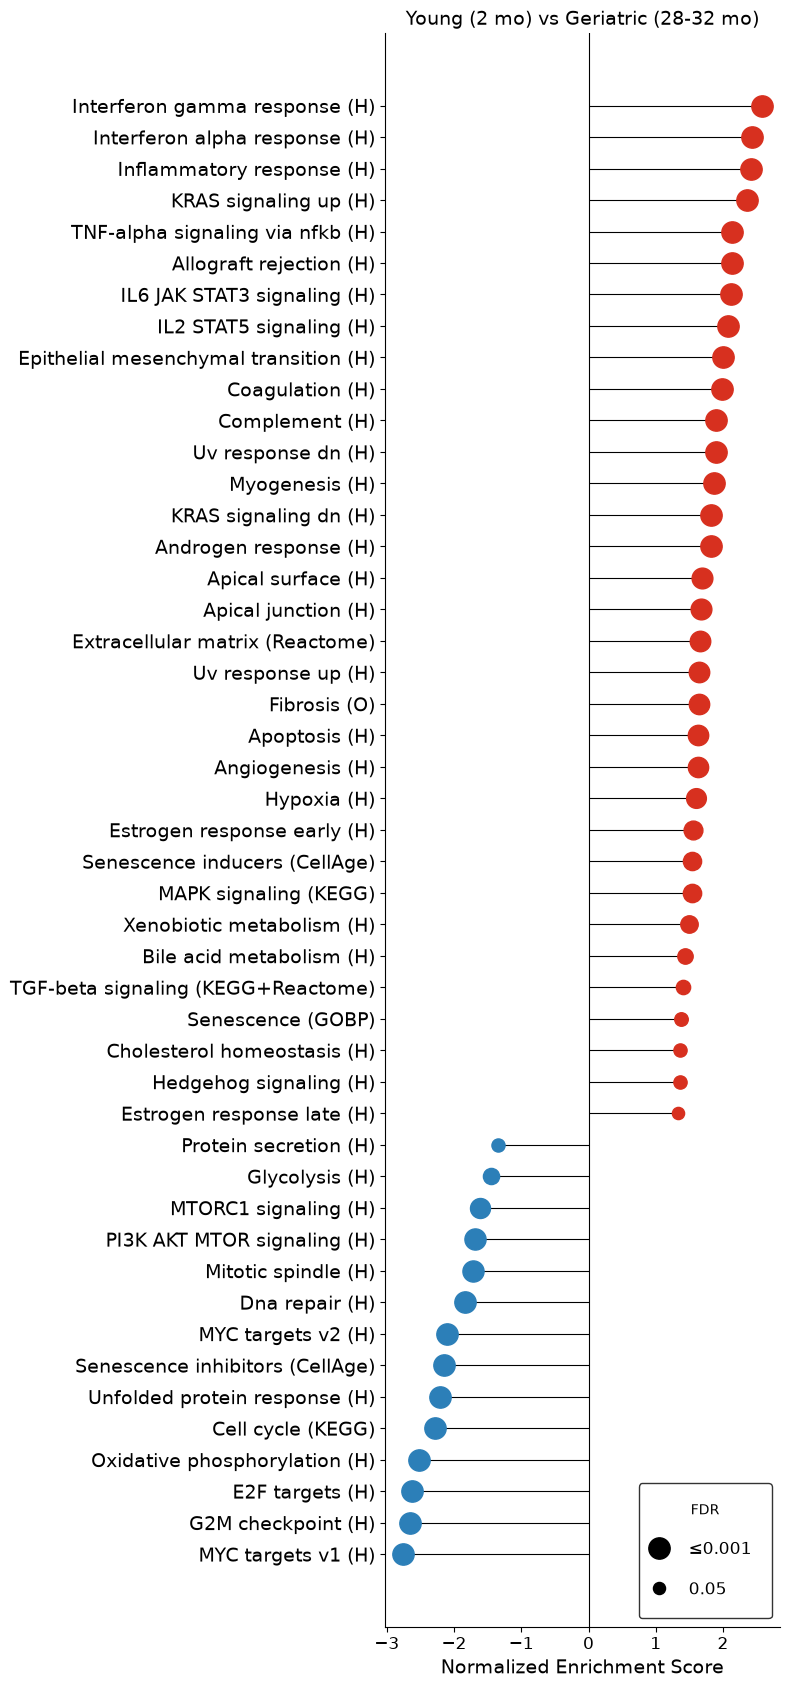

In [7]:
gsea_panel("young_vs_geriatric", "Young (2 mo) vs Geriatric (28-32 mo)", "fig4Sa_a_gsea_young_vs_geriatric")

### Supplementary Figure 4Sa, panel c — Differentially expressed pathways, young vs aged

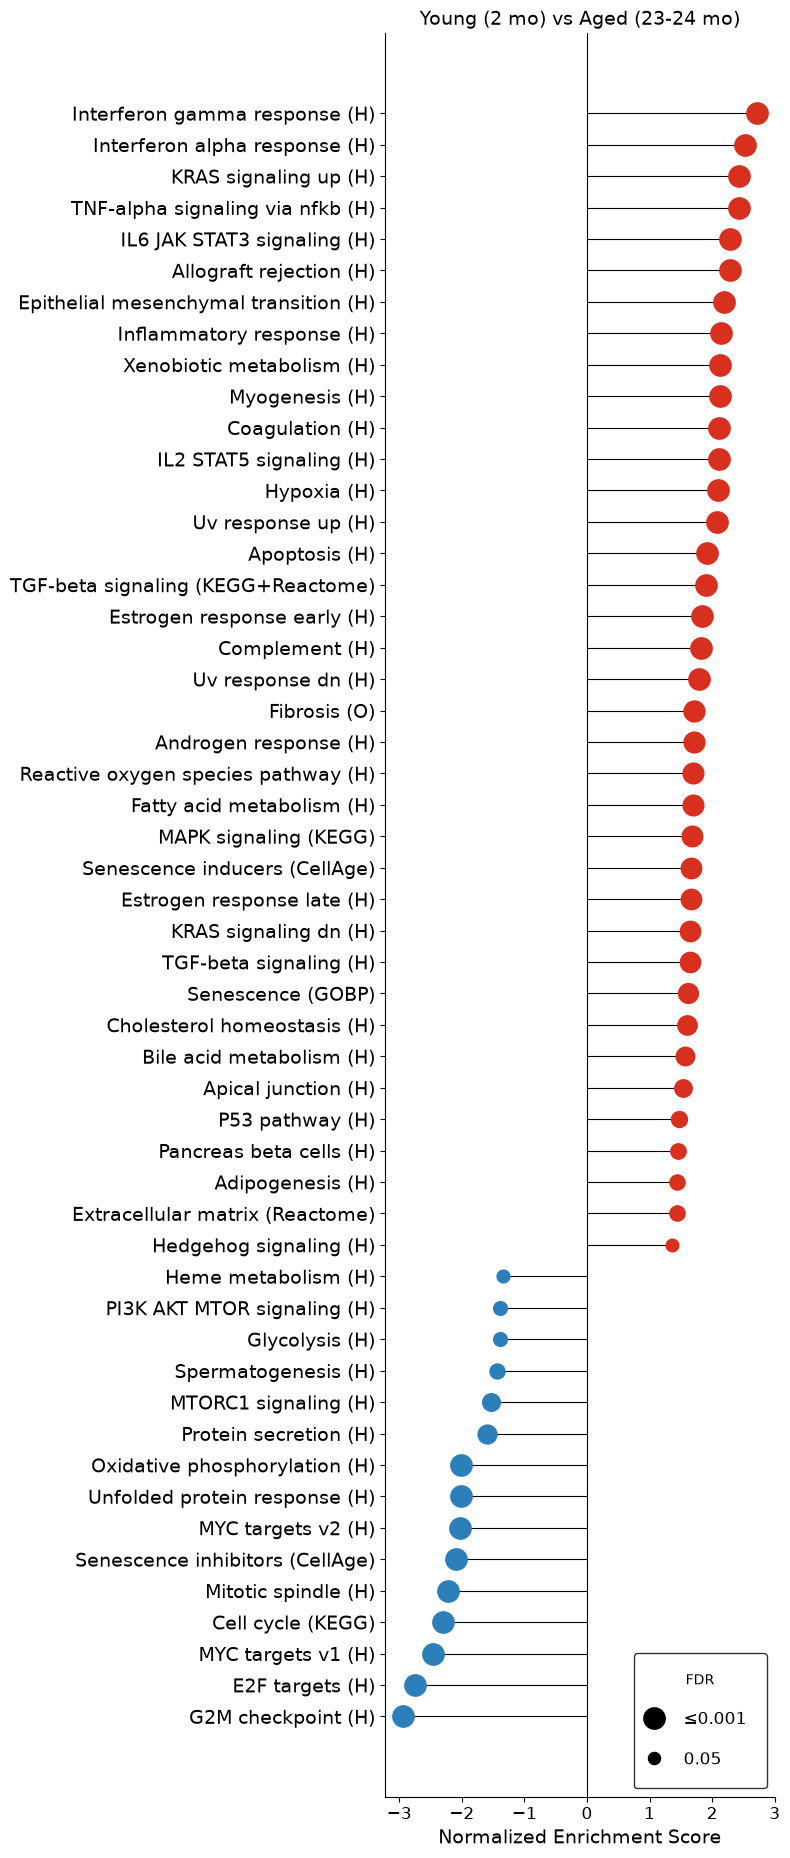

In [8]:
gsea_panel("young_vs_aged", "Young (2 mo) vs Aged (23-24 mo)", "fig4Sa_c_gsea_young_vs_aged")

### Supplementary Figure 4Sa, panel d — Differentially expressed pathways, aged vs geriatric

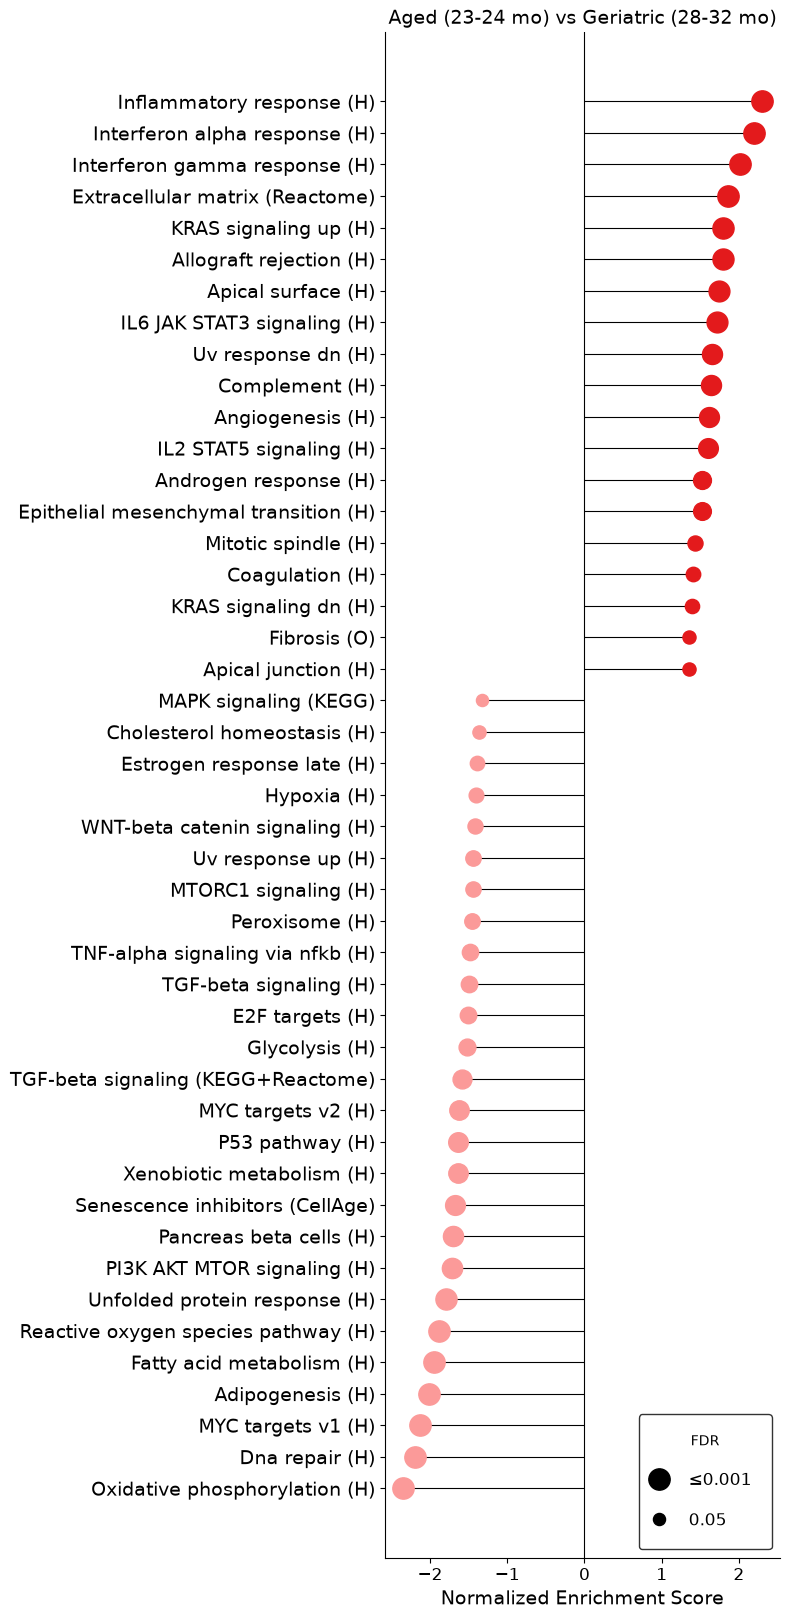

In [9]:
gsea_panel(AG, "Aged (23-24 mo) vs Geriatric (28-32 mo)", "fig4Sa_d_gsea_aged_vs_geriatric", up_color=GERI_C,
           down_color=AGED_C)

## Colocalization vs expression
### Figure 4c — Colocalization vs expression, young vs geriatric
x = GSEA NES (geriatric vs young), y = log2(old fold / young fold); colour = per-state hypergeometric FDR < 0.05;
interferon, complement, inflammatory response and fibrosis outlined and labelled.

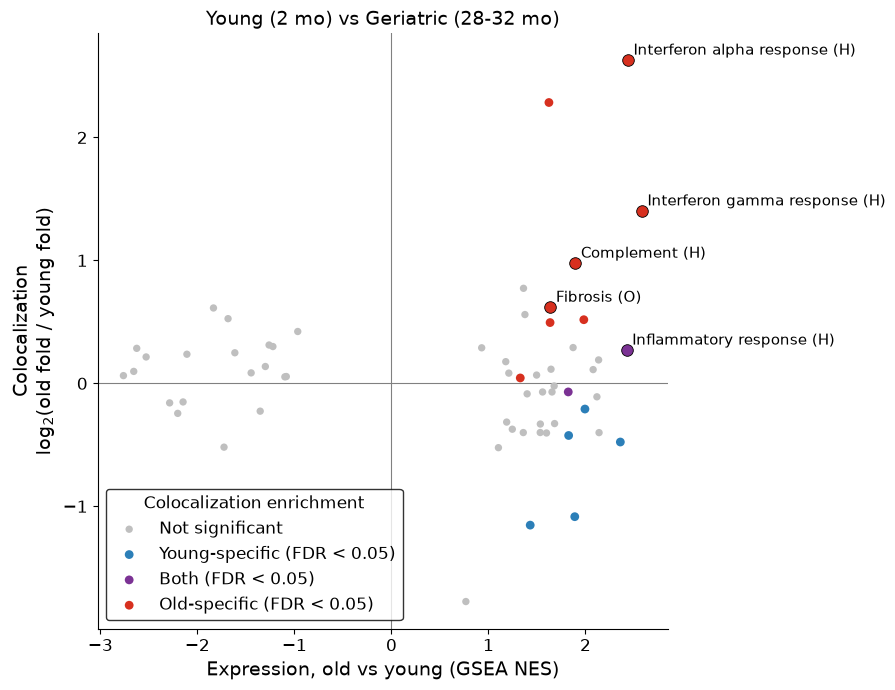

In [10]:
HIGHLIGHT = ["Interferon gamma response (H)", "Interferon alpha response (H)",
             "Complement (H)", "Inflammatory response (H)", "Fibrosis (O)"]
pair = "young_vs_geriatric"
f = folds[pair]
g = gsea[pair]
common = [p for p in f.index if p in g.index]
x = g.loc[common, "NES"].astype(float).values                     # transcription
with np.errstate(divide="ignore", invalid="ignore"):              # a zero fold -> +/-inf (scatter skips)
    y = np.log2((f.loc[common, "fold_old"] / f.loc[common, "fold_young"]).astype(float).values)
old_sig = f.loc[common, "fdr_old"] < SIG
young_sig = f.loc[common, "fdr_young"] < SIG
cat = np.where(old_sig & young_sig, "both", np.where(old_sig, "old", np.where(young_sig, "young", "ns")))
colors = {"old": OLD, "young": YOUNG, "both": BOTH, "ns": GREY}
names = {"old": "Old-specific (FDR < 0.05)", "young": "Young-specific (FDR < 0.05)",
         "both": "Both (FDR < 0.05)", "ns": "Not significant"}

fig, ax = plt.subplots(figsize=(9, 7))
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
for k in ["ns", "young", "both", "old"]:
    m = cat == k
    if m.any():
        ax.scatter(x[m], y[m], s=28 if k == "ns" else 40, color=colors[k], edgecolor="none",
                   zorder=2 if k == "ns" else 3, label=names[k])
for p in HIGHLIGHT:
    if p not in common:
        continue
    i = common.index(p)
    if not (np.isfinite(x[i]) and np.isfinite(y[i])):
        continue
    ax.scatter(x[i], y[i], s=70, color=colors[cat[i]], edgecolor="black", linewidth=0.6, zorder=4)
    ax.annotate(label_of(p), (x[i], y[i]), fontsize=11, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Expression, old vs young (GSEA NES)", fontsize=14)
ax.set_title("Young (2 mo) vs Geriatric (28-32 mo)", fontsize=14)
ax.tick_params(labelsize=12)
ax.legend(loc="lower left", fontsize=12, frameon=True, edgecolor="black",
          title="Colocalization enrichment", title_fontsize=12)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.set_ylabel("Colocalization\nlog$_2$(old fold / young fold)", fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIG}/fig4c_concordance_young_vs_geriatric.svg", bbox_inches="tight")
plt.show()

## Locus-matched permutation test
−log10 nominal p for pathways with p ≤ 0.1 (younger state left, older right; full colour p < 0.05, light p ≤ 0.1).

In [11]:
def panel_locus(d, a, b, title, ca, cb, la, lb, name):
    """Mirrored -log10 nominal p bars (state a left, state b right); dark p < 0.05, light p <= 0.1."""
    keep = d[(d[f"locus_p_{a}"] <= 0.1) | (d[f"locus_p_{b}"] <= 0.1)]
    right = keep[f"locus_p_{b}"] <= keep[f"locus_p_{a}"]
    r = pd.concat([keep[~right].sort_values(f"locus_p_{a}"),                      # state-a block at the bottom
                   keep[right].sort_values(f"locus_p_{b}", ascending=False)])     # state-b block on top
    h = 0.4 * max(len(r), 3) + 2.2
    fig, ax = plt.subplots(figsize=(8, h))
    for i, (_, x) in enumerate(r.iterrows()):
        for p, side, col in ((x[f"locus_p_{a}"], -1, ca), (x[f"locus_p_{b}"], 1, cb)):
            if p <= 0.1:
                ax.barh(i, side * -np.log10(p), height=0.72, color=col if p < 0.05 else light(col), zorder=3)
    for s in (-1, 1):
        ax.axvline(s * -np.log10(0.05), color="black", lw=0.7, ls="--", zorder=2)
    ax.axvline(0, color="black", lw=0.8, zorder=4)
    lim = max(2.0, np.ceil((-np.log10(r[[f"locus_p_{a}", f"locus_p_{b}"]].min().min()) + 0.3) * 2) / 2)
    ticks = np.arange(0, lim + 0.01, 1)                              # whole-number ticks stay legible
    tick_pos = np.r_[-ticks[:0:-1], ticks]                            # mirrored: state a to the left of 0
    ax.set_xticks(tick_pos, [f"{abs(t):g}" for t in tick_pos], fontsize=15)
    ax.set_xlim(-lim, lim)
    ax.set_yticks(range(len(r)), r.set, fontsize=17)
    ax.set_ylim(-0.6, len(r) - 0.4)
    ax.set_xlabel("−log10 nominal p\n(locus-matched permutation)", fontsize=17)
    ax.set_title(title, fontsize=17)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis="y", length=0)
    fig.legend(handles=[Patch(color=cb, label=f"{lb}, p < 0.05"), Patch(color=light(cb), label=f"{lb}, p ≤ 0.1"),
                        Patch(color=ca, label=f"{la}, p < 0.05"), Patch(color=light(ca), label=f"{la}, p ≤ 0.1")],
               loc="lower center", ncol=2, frameon=True, edgecolor="black", fontsize=14,
               # centred on the plot area (x in axes units), at the bottom of the figure (y in figure units)
               bbox_to_anchor=(0.5, 0), bbox_transform=blended_transform_factory(ax.transAxes, fig.transFigure))
    plt.tight_layout(rect=(0, 0.95 / h, 1, 1))                     # reserve ~0.95 in under the axis for the legend
    plt.savefig(f"{FIG}/{name}.svg", bbox_inches="tight")
    plt.show()

### Supplementary Figure 4Sb, panel a — Locus-matched test, young vs geriatric

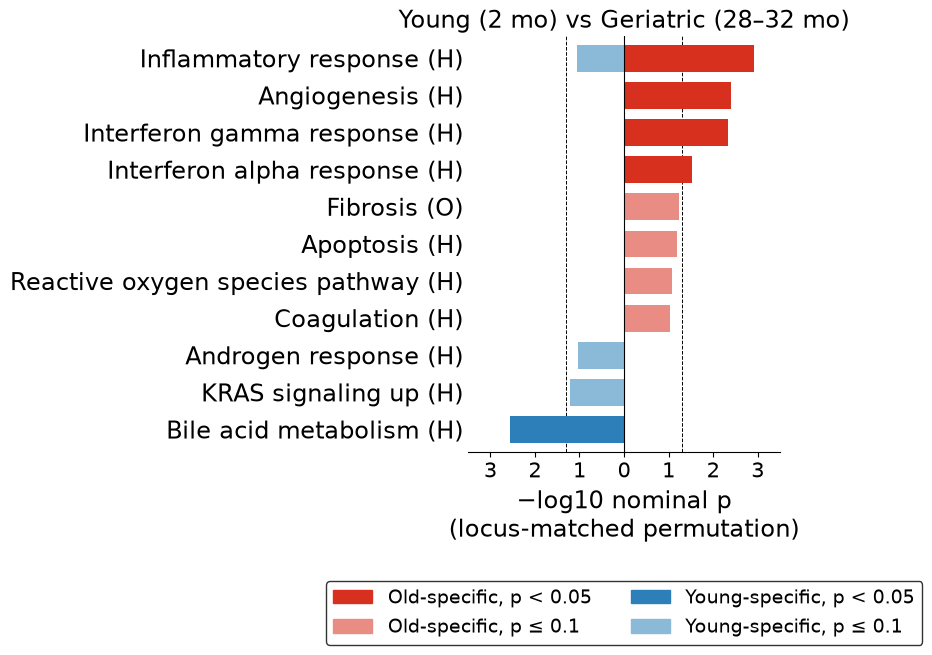

In [12]:
panel_locus(pd.read_csv(f"{DATA}/locus_matched_young_vs_geriatric.csv"), "young", "geriatric",
            "Young (2 mo) vs Geriatric (28–32 mo)", YOUNG, OLD, "Young-specific", "Old-specific",
            "fig4Sb_a_locus_matched_young_vs_geriatric")

### Supplementary Figure 4Sb, panel b — Locus-matched test, aged vs geriatric

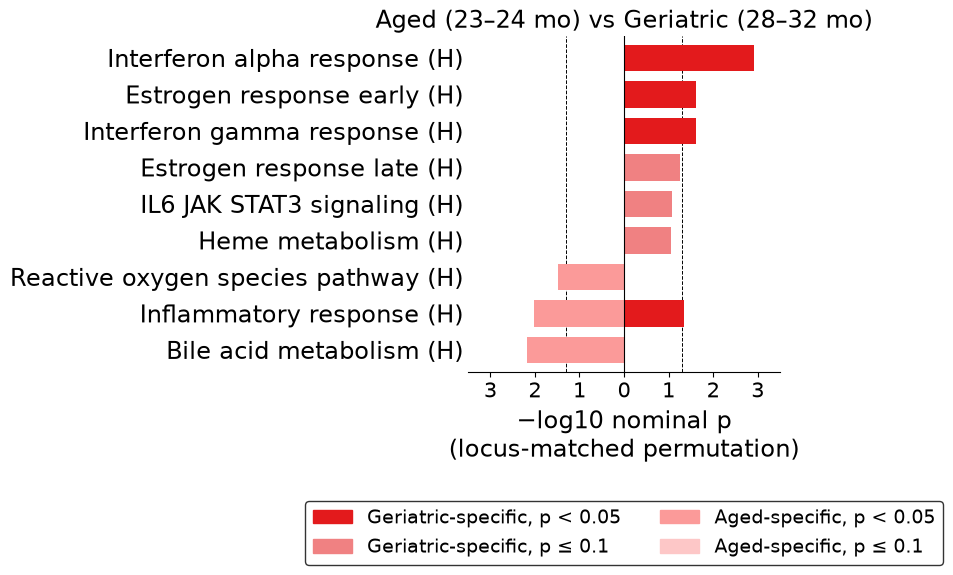

In [13]:
panel_locus(pd.read_csv(f"{DATA}/locus_matched_aged_vs_geriatric.csv"), "aged", "geriatric",
            "Aged (23–24 mo) vs Geriatric (28–32 mo)", AGED_C, GERI_C, "Aged-specific", "Geriatric-specific",
            "fig4Sb_b_locus_matched_aged_vs_geriatric")

## State-specific k-cores
Gene × gene contact-state heatmaps of the geriatric-only cores (`data/muscle/kcores/`), genes in genomic order, with
chromosome strips (shared `../kcore.py`). Boxes are drawn at equal size (aspect auto); the state legend sits underneath.

In [14]:
cmap = ListedColormap(["#f2f2f2", YOUNG, GREY, OLD])  # codes 0 none, 1 young-only, 2 shared, 3 geriatric-only
norm = BoundaryNorm([-.5, .5, 1.5, 2.5, 3.5], cmap.N)
core_legend = [Patch(facecolor=OLD, label="Geriatric-only"),
               Patch(facecolor=YOUNG, label="Young-only"),
               Patch(facecolor=GREY, label="Shared")]
CORE_INFO = pd.read_csv(f"{DATA}/kcores/kcore_summary.csv").set_index("core")


def draw_core(ax, core, title, tick_fs):
    """One core heatmap with chromosome strips on an existing axis."""
    genes = pd.read_csv(f"{DATA}/kcores/{core}_genes.csv")
    M = pd.read_csv(f"{DATA}/kcores/{core}_states.csv", index_col=0).to_numpy()
    ax.imshow(M, cmap=cmap, norm=norm, aspect="auto")  # aspect auto -> equal-size boxes
    chroms = [int(c.removeprefix("chr")) for c in genes.chrom]
    kcore.chrom_strips(ax, genes.gene.tolist(), chroms, tick_fs, strip_size=0.28, min_number_fs=6)
    ax.set_title(title, fontsize=15)


def core_legend_below(fig):
    """Framed contact-state legend under the heatmaps."""
    fig.legend(handles=core_legend, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.0),
               fontsize=13, frameon=True, edgecolor="black", title=None,
               title_fontsize=14, columnspacing=2.0, handletextpad=0.8)


print(CORE_INFO.to_string())

                                  pathway   k  n_genes  n_chromosomes  pairs_young  pairs_Shared  pairs_geriatric
core                                                                                                             
ifng        Interferon gamma response (H)  13       37              8            9           112              323
ifna        Interferon alpha response (H)   8       30              8            4            80              179
complement                 Complement (H)   8       49             13           31           371              291


### Figure 4d — Interferon-γ response, geriatric-specific core

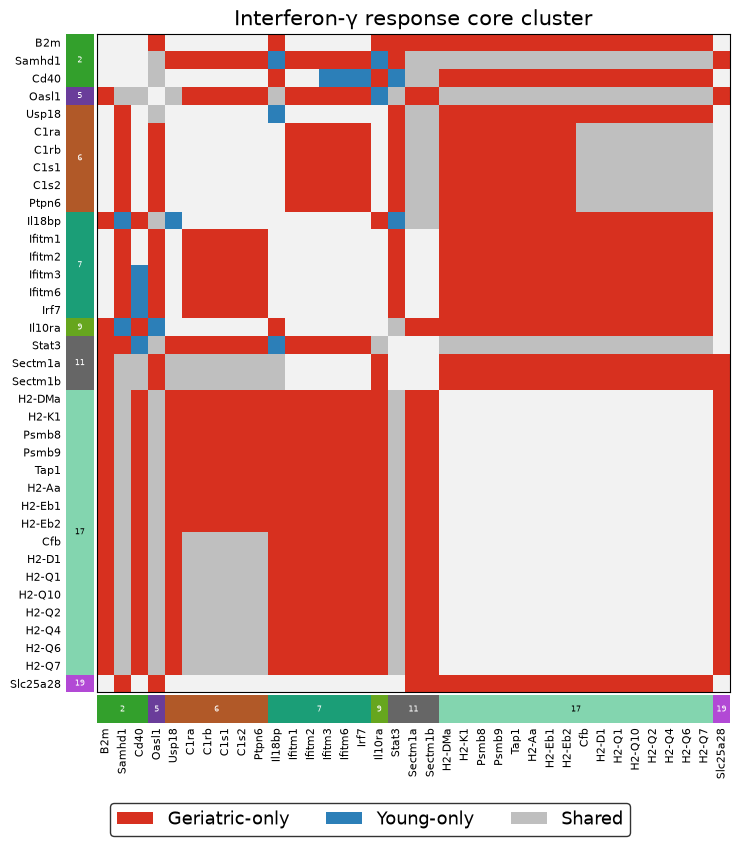

In [15]:
fig, axes = plt.subplots(1, 1, figsize=(7.5, 8), squeeze=False)
draw_core(axes[0][0], "ifng", "Interferon-γ response core cluster", 8)
plt.tight_layout()
core_legend_below(fig)
plt.savefig(f"{FIG}/fig4d_ifng_core.svg", bbox_inches="tight")
plt.show()

### Supplementary Figure 4Sb, panel c — Interferon-α response and complement, geriatric-specific cores

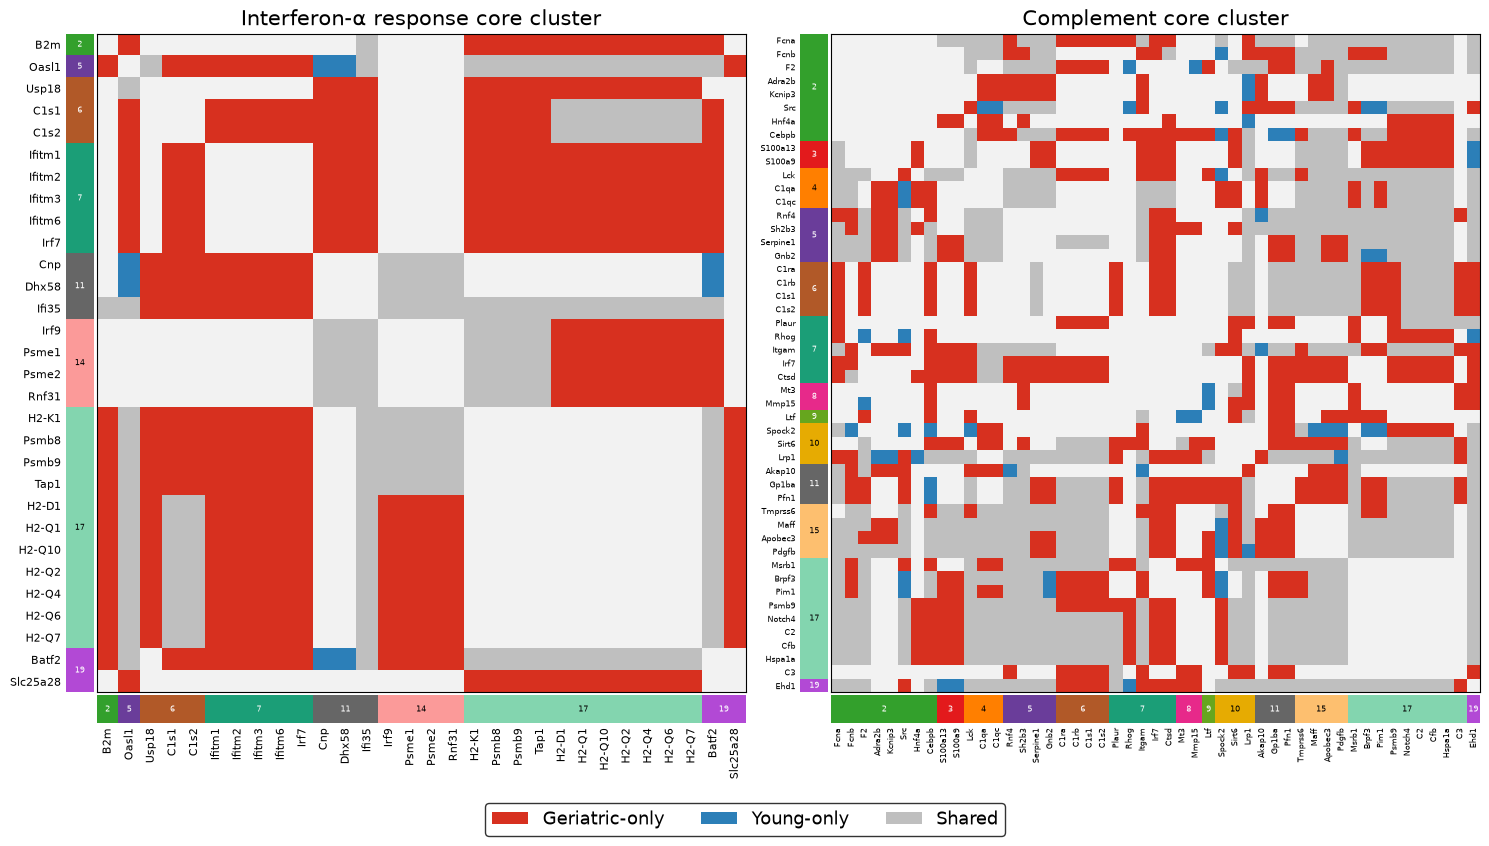

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), squeeze=False)
draw_core(axes[0][0], "ifna", "Interferon-α response core cluster", 8)
draw_core(axes[0][1], "complement", "Complement core cluster", 6)
plt.tight_layout()
core_legend_below(fig)
plt.savefig(f"{FIG}/fig4Sb_c_ifna_complement_cores.svg", bbox_inches="tight")
plt.show()

## Age trajectory of colocalization
Excess over a size-matched random-gene null per age (`data/muscle/trajectory_*.csv`) and the net-accumulation sweep
(`data/muscle/net_accumulation_sweep.csv`). Old-enriched pathways red, young-enriched blue, other stable pathways grey.

In [17]:
AGES = ["young", "aged", "geriatric"]
AGE_LABELS = {"young": "Young\n(2 mo)", "aged": "Aged\n(23–24 mo)", "geriatric": "Geriatric\n(28–32 mo)"}
SHORT = {"Interferon gamma response (H)": "IFN-γ", "Interferon alpha response (H)": "IFN-α", "Complement (H)": "Complement",
         "Fibrosis (O)": "Fibrosis", "Uv response dn (H)": "UV response dn", "KRAS signaling dn (H)": "KRAS sig dn",
         "Bile acid metabolism (H)": "Bile acid metabolism"}
GROUPS = {"Old-enriched": (["Interferon gamma response (H)", "Interferon alpha response (H)",
                            "Complement (H)", "Fibrosis (O)"], OLD),
          "Young-enriched": (["Bile acid metabolism (H)", "Uv response dn (H)", "KRAS signaling dn (H)"], YOUNG)}
highlight = set(GROUPS["Old-enriched"][0]) | set(GROUPS["Young-enriched"][0])
age_x = np.arange(3)                                   # x positions of the three ages


def spread_labels(label_slots, min_gap):
    """Push right-edge labels apart so consecutive ones are at least min_gap apart (sorted by height)."""
    label_slots.sort()
    for i in range(1, len(label_slots)):
        if label_slots[i][0] - label_slots[i - 1][0] < min_gap:
            label_slots[i][0] = label_slots[i - 1][0] + min_gap
    return label_slots

### Figure 4f — Colocalization over age, relative to young

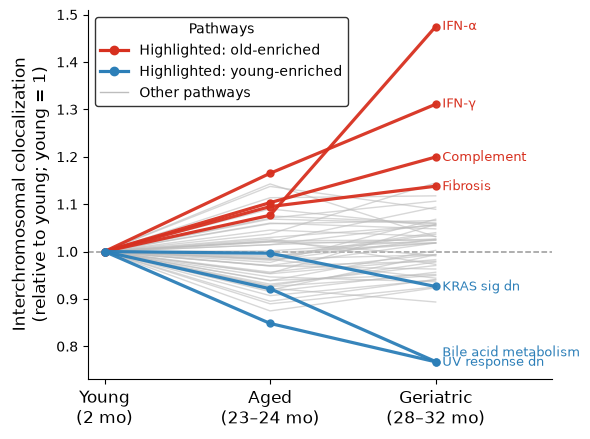

In [18]:
landscape = {name: row.to_numpy(float) for name, row in
             pd.read_csv(f"{DATA}/trajectory_relative.csv", index_col=0)[AGES].iterrows()}
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.axhline(1, color="0.6", ls="--", lw=1.1, zorder=1)
for name, traj in landscape.items():                    # grey context: every stable pathway not highlighted
    if name in highlight:
        continue
    ax.plot(age_x, traj, "-", color="0.74", lw=1.0, alpha=0.6, zorder=2)
label_slots = []
for names, color in (GROUPS["Old-enriched"], GROUPS["Young-enriched"]):
    for name in names:
        if name not in landscape:
            continue
        ax.plot(age_x, landscape[name], "-o", color=color, lw=2.3, ms=5, alpha=0.95, zorder=4)
        label_slots.append([landscape[name][2], SHORT[name], color])
for y_label, name, color in spread_labels(label_slots, 0.02):
    ax.text(2.04, y_label, name, color=color, fontsize=9, va="center",)
ax.set_xlim(-0.1, 2.7)
ax.set_xticks(age_x,)
ax.set_xticklabels([AGE_LABELS[a] for a in AGES], fontsize = 12)
ax.set_ylabel("Interchromosomal colocalization\n(relative to young; young = 1)", fontsize=12)
handles = [plt.Line2D([], [], color=OLD, lw=2.3, marker="o", label="Highlighted: old-enriched"),
           plt.Line2D([], [], color=YOUNG, lw=2.3, marker="o", label="Highlighted: young-enriched"),
           plt.Line2D([], [], color="0.74", lw=1.0, label=f"Other pathways")]
ax.legend(handles=handles, fontsize=10, loc="upper left", title = "Pathways", frameon=True, edgecolor="black")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(f"{FIG}/fig4f_colocalization_over_age.svg", bbox_inches = 'tight')
plt.show()

### Figure 4g — Net age-gained colocalization vs the random-gene null
Old-enriched pathways from the sweep; FDR < 0.05 in colour, else grey; tick = size-matched random-gene null.

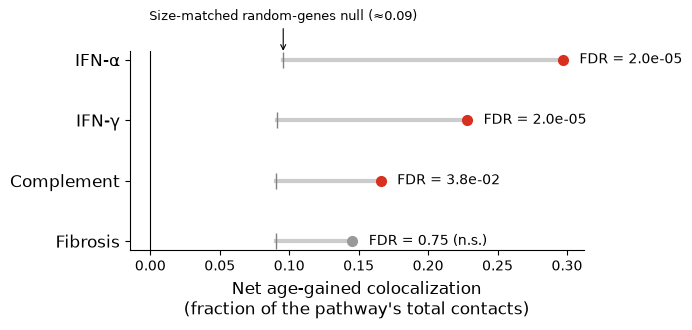

In [19]:
sweep = pd.read_csv(f"{DATA}/net_accumulation_sweep.csv")
gained = sweep[sweep["direction"] == "gained"].set_index("pathway")
show = [p for p in GROUPS["Old-enriched"][0] if p in gained.index]
show = sorted(show, key=lambda name: gained.loc[name, "net"])

fig, ax = plt.subplots(figsize=(7, 3.4))
for yi, name in enumerate(show):
    row = gained.loc[name]
    significant = row["fdr"] < 0.05
    ax.plot([row["null_mean"], row["net"]], [yi, yi], color="0.8", lw=3, zorder=1)
    ax.plot(row["null_mean"], yi, "|", color="0.5", ms=12, zorder=2)
    ax.plot(row["net"], yi, "o", ms=7, color=(OLD if significant else "0.6"), zorder=3)
    tag = f"  FDR = {row['fdr']:.1e}" if significant else f"  FDR = {row['fdr']:.2f} (n.s.)"
    ax.text(row["net"] + 0.006, yi, tag, va="center", fontsize=10)
top = len(show) - 1                                     # name the random-gene null once, at the top row's tick
ax.annotate("Size-matched random-genes null (≈0.09)",
            (gained.loc[show[top], "null_mean"], top + 0.1),
            xytext=(0, 22), textcoords="offset points", ha="center", va="bottom",
            fontsize=9,
            arrowprops=dict(arrowstyle="->",  lw=0.8))
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(show)))
ax.set_yticklabels([SHORT.get(name, name) for name in show], fontsize = 12)
ax.set_xlabel("Net age-gained colocalization\n(fraction of the pathway's total contacts)", fontsize=12)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(f"{FIG}/fig4g_net_accumulation.svg", bbox_inches = 'tight')
plt.show()

### Supplementary Figure 4Sa, panel e — Absolute colocalization level over age
Excess over the random-gene null (1 = random-gene level), not normalized to young: level is orthogonal to the aging change.

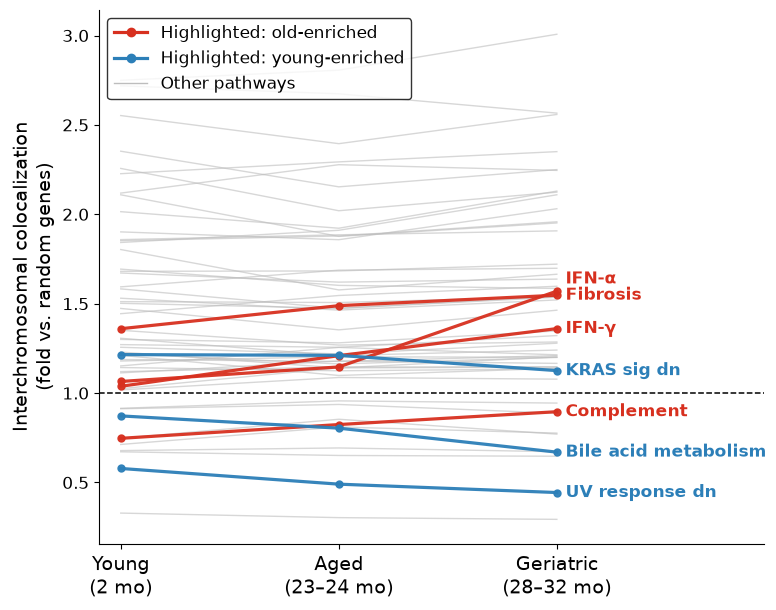

In [20]:
levels = {name: row.to_numpy(float) for name, row in
          pd.read_csv(f"{DATA}/trajectory_absolute.csv", index_col=0)[AGES].iterrows()}
fig, ax = plt.subplots(figsize=(8, 6.2))
ax.axhline(1, color = 'black', ls="--", lw=1.1, zorder=1)
for name, lev in levels.items():
    if name in highlight:
        continue
    ax.plot(age_x, lev, "-", color="0.74", lw=1.0, alpha=0.6, zorder=2)
label_slots = []
for names, color in GROUPS.values():
    for name in names:
        if name not in levels:
            continue
        ax.plot(age_x, levels[name], "-o", color=color, lw=2.3, ms=5, alpha=0.95, zorder=4)
        label_slots.append([levels[name][2], SHORT.get(name, name), color])
for y_label, name, color in spread_labels(label_slots, 0.09):
    ax.text(2.04, y_label, name, color=color, fontsize=12, va="center", fontweight="bold")
ax.set_xlim(-0.1, 2.95)
ax.set_xticks(age_x)
ax.set_xticklabels([AGE_LABELS[a] for a in AGES])
ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=14)                  # age categories act as the x label
ax.set_ylabel("Interchromosomal colocalization\n(fold vs. random genes)", fontsize=14)
handles = [plt.Line2D([], [], color=color, lw=2.3, marker="o", label=f"Highlighted: {gname.lower()}")
           for gname, (names, color) in GROUPS.items()]
handles.append(plt.Line2D([], [], color="0.74", lw=1.0, label=f"Other pathways"))
ax.legend(handles=handles, fontsize=12, loc="upper left", frameon=True, edgecolor="black")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(f"{FIG}/fig4Sa_e_absolute_colocalization.svg", bbox_inches = 'tight')
plt.show()